<a href="https://colab.research.google.com/github/d3m1d0s/FoML_exercises/blob/main/fml_05_student_en_active_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fundamentals of Machine Learning — Exercise 5

## Gradient Descent, Linear Regression, and Logistic Regression

The previous exercises focused on finding structure without a target variable. We now move to **supervised learning**.

This exercise follows one central idea:

> A model is fitted by changing its parameters so that a loss function becomes smaller.

We will use gradient descent first for regression and then for binary classification.

The working rhythm remains:

> **question → prediction → computation → visualisation → interpretation → verification**

### Learning outcomes

After completing this exercise, you should be able to:

- explain the roles of features, targets, predictions, residuals, and loss,
- describe a gradient as a direction of local change,
- perform and verify one gradient-descent update by hand,
- explain the effect of the learning rate,
- fit linear regression using a prepared NumPy implementation,
- explain why logistic regression produces probabilities,
- distinguish probability estimation from the final decision threshold,
- interpret a confusion matrix, precision, recall, F1-score, and ROC-AUC,
- explain why accuracy can be misleading for an imbalanced dataset,
- avoid fitting preprocessing on the test set,
- use AI as a tutor that questions reasoning instead of generating the solution.

**Recommended duration:** 110–120 minutes.

## How to work in this exercise

Most implementation is prepared. Your main tasks are to:

1. make a prediction before running an experiment,
2. complete a small number of mathematically meaningful lines,
3. explain the result using the loss function and model behaviour,
4. verify an important claim numerically,
5. distinguish a modelling decision from a software default.

Do not judge a model from one metric alone.

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes, make_classification
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42

## 1. A line, its predictions, and its errors

For one feature, a linear model is

$$
\hat{y} = wx + b.
$$

- `w` is the slope,
- `b` is the intercept,
- `y - ŷ` is a residual.

We will begin with a tiny dataset where the correct relationship is almost visible.

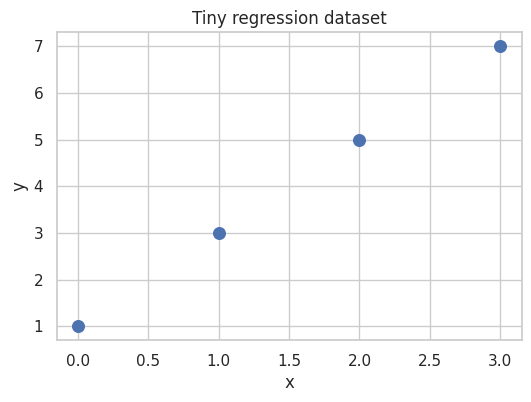

In [2]:
x_small = np.array([0.0, 1.0, 2.0, 3.0])
y_small = np.array([1.0, 3.0, 5.0, 7.0])

plt.figure(figsize=(6, 4))
plt.scatter(x_small, y_small, s=70)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Tiny regression dataset')
plt.show()

### Predict before computing

1. What values of `w` and `b` appear plausible?
- `w = 2` and `b = 1`: `y` grows by 2 for each step of 1 in `x`, and `y = 1` at `x = 0`. All four points lie exactly on the line `y = 2x + 1`

2. If we start with `w=0` and `b=0`, will the model underpredict or overpredict?
- underpredict: every prediction is 0, but the observed values are 1, 3, 5 and 7, so all residuals `y - ŷ` are positive

3. Should the next update increase or decrease `w`?
- increase: the model starts at `w = 0`, but the points suggest `w = 2`, so `w` has to grow

In [3]:
def predict_linear(x, w, b):
    return w * x + b


def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


w0, b0 = 0.0, 0.0
prediction0 = predict_linear(x_small, w0, b0)

pd.DataFrame({
    'x': x_small,
    'y': y_small,
    'prediction': prediction0,
    'residual_y_minus_prediction': y_small - prediction0,
})

,x,y,prediction,residual_y_minus_prediction
0,0.0,1.0,0.0,1.0
1,1.0,3.0,0.0,3.0
2,2.0,5.0,0.0,5.0
3,3.0,7.0,0.0,7.0


In [4]:
print('Initial MSE:', mse_loss(y_small, prediction0))

Initial MSE: 21.0


## 2. One gradient-descent step

For mean squared error, the gradients for a one-feature model are

$$
\frac{\partial MSE}{\partial w} = \frac{2}{n}\sum_i x_i(\hat{y}_i-y_i),
\qquad
\frac{\partial MSE}{\partial b} = \frac{2}{n}\sum_i (\hat{y}_i-y_i).
$$

Gradient descent updates parameters in the **opposite** direction:

$$
w_{new}=w-\alpha\frac{\partial MSE}{\partial w},
\qquad
b_{new}=b-\alpha\frac{\partial MSE}{\partial b}.
$$

Here `α` is the learning rate.

### Activity 1 — Complete only the meaningful lines

Fill the two gradient expressions. Do not rewrite the surrounding function.

In [5]:
def linear_gradients(x, y, w, b):
    prediction = predict_linear(x, w, b)
    error = prediction - y

    # TODO: replace the two lines below.
    grad_w = (2 / len(x)) * np.sum(x * error)
    grad_b = (2 / len(x)) * np.sum(error)

    return grad_w, grad_b


grad_w0, grad_b0 = linear_gradients(x_small, y_small, w0, b0)
print('Gradient for w:', grad_w0)
print('Gradient for b:', grad_b0)

Gradient for w: -17.0
Gradient for b: -8.0


Before running the update, interpret the signs:

> A negative gradient for `w` means that increasing `w` should decrease the loss locally.
>
> We subtract the gradient, therefore the new `w` will increase: the gradient here is −17, and subtracting a negative number makes `w` larger.

In [6]:
LEARNING_RATE = 0.05

w1 = w0 - LEARNING_RATE * grad_w0
b1 = b0 - LEARNING_RATE * grad_b0
prediction1 = predict_linear(x_small, w1, b1)

print('Updated w:', w1)
print('Updated b:', b1)
print('MSE before:', mse_loss(y_small, prediction0))
print('MSE after one step:', mse_loss(y_small, prediction1))

Updated w: 0.8500000000000001
Updated b: 0.4
MSE before: 21.0
MSE after one step: 7.05875


### Verification

Did the loss decrease? If not, which parts would you inspect first?

- gradient formula,
- update sign,
- learning rate,
- data shape.

**Answer:**
- yes: the MSE fell from 21.0 to about 7.06 after one step. `w` moved from 0 to 0.85 and `b` from 0 to 0.4, both in the direction of the values suggested by the plot (2 and 1), but still far from them, so more steps are needed
- the update can be checked by hand: `0 - 0.05 · (-17) = 0.85` and `0 - 0.05 · (-8) = 0.4`, the same values as printed
- if the loss had not decreased, I would first check whether the code matches the formulas, that is, the gradient lines and the update sign, because they decide the direction of the step. A quick test: w has to grow, so its gradient must be negative. If the code matches the formulas, the learning rate is the only remaining cause, because a step that is too large can overshoot even in the right direction. The data shape last

## 3. Learning rate: too small, useful, or unstable?

We now run the same algorithm for several learning rates.

Predict first:

| Learning rate | Expected behaviour |
|---:|---|
| 0.001 | steps 50 times smaller than with 0.05: the loss falls very slowly and is still high after 80 steps |
| 0.05 | one step already took the loss from 21 to about 7, so it should fall fast and stay stable at a low value |
| 0.50 | the first step would change `w` by 0.50 · 17 = 8.5, far past 2, so it overshoots and the loss grows |

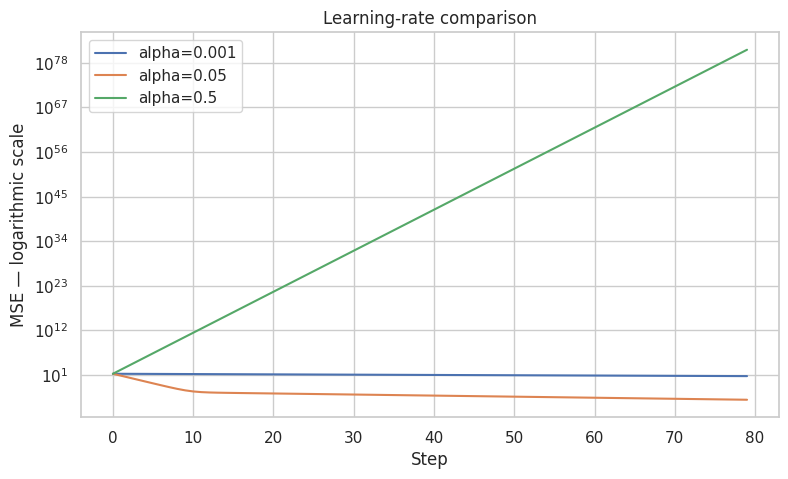

In [7]:
def fit_linear_gd(x, y, learning_rate, n_steps=80):
    w, b = 0.0, 0.0
    history = []

    for step in range(n_steps):
        prediction = predict_linear(x, w, b)
        loss = mse_loss(y, prediction)
        history.append({'step': step, 'loss': loss, 'w': w, 'b': b})

        grad_w, grad_b = linear_gradients(x, y, w, b)
        w -= learning_rate * grad_w
        b -= learning_rate * grad_b

        if not np.isfinite(w + b):
            break

    return w, b, pd.DataFrame(history)


learning_rates = [0.001, 0.05, 0.50]
linear_runs = {}

plt.figure(figsize=(9, 5))

for rate in learning_rates:
    w_fit, b_fit, history = fit_linear_gd(
        x_small,
        y_small,
        learning_rate=rate,
        n_steps=80,
    )
    linear_runs[rate] = (w_fit, b_fit, history)
    plt.plot(history['step'], history['loss'], label=f'alpha={rate}')

plt.yscale('log')
plt.xlabel('Step')
plt.ylabel('MSE — logarithmic scale')
plt.title('Learning-rate comparison')
plt.legend()
plt.show()

### Activity 2 — Explain the trajectories

For each learning rate, describe:

- speed of progress,
- stability,
- final loss.

**Answer:**
- `alpha=0.001`: very slow, the curve is almost flat. It is stable, the loss falls steadily without jumps, but after 80 steps it is still close to where it started
- `alpha=0.05`: fast, the loss drops steeply in the first ten steps and then keeps falling slowly. It is stable and ends with the lowest loss of the three
- `alpha=0.5`: no progress at all, the loss grows from the first step. On the logarithmic scale it rises in a straight line, roughly by a power of ten per step, up to about 10^80, so every step overshoots further
- because the axis has to reach 10^80 for `alpha=0.5`, the other two curves are squeezed at the bottom of the plot, so their exact final values cannot be read from it

Then complete:

> A learning rate is not “good” because it is large or small. It is useful when its steps are large enough to make fast progress but small enough not to overshoot, so that the loss falls steadily, as with `alpha=0.05` here.

## 4. Linear regression on real data

We use the built-in diabetes regression dataset. The target is a quantitative disease-progression measure one year after baseline.

We will compare:

- our NumPy gradient-descent model,
- scikit-learn's direct `LinearRegression` solution.

To keep the from-scratch model readable, we use one feature: `bmi`.

In [8]:
diabetes = load_diabetes(as_frame=True)
diabetes_frame = diabetes.frame.copy()

display(diabetes_frame[['bmi', 'target']].head())

X_reg = diabetes_frame[['bmi']].to_numpy()
y_reg = diabetes_frame['target'].to_numpy()

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.25,
    random_state=RANDOM_STATE,
)

x_scaler = StandardScaler()
y_mean = y_train_reg.mean()
y_std = y_train_reg.std()

X_train_reg_scaled = x_scaler.fit_transform(X_train_reg).ravel()
X_test_reg_scaled = x_scaler.transform(X_test_reg).ravel()
y_train_reg_scaled = (y_train_reg - y_mean) / y_std

,bmi,target
0,0.061696,151.0
1,-0.051474,75.0
2,0.044451,141.0
3,-0.011595,206.0
4,-0.036385,135.0


### Leakage checkpoint

Why is the scaler fitted only on the training set?
- the test set stands for new patients that the model has never seen. The scaler learns the mean and standard deviation of `bmi` from the data it is fitted on, just as the model later learns `w` and `b`, so it may use only the training data. The test data are then scaled with the training values (`transform`, not `fit_transform`)

What information from the test set would leak if we fitted it before splitting?
- the mean and standard deviation of the test patients would be mixed into the values used to scale the training data. The model would get a small look at the test set, so the test error would no longer be an honest check on new patients

In [9]:
w_reg, b_reg, reg_history = fit_linear_gd(
    X_train_reg_scaled,
    y_train_reg_scaled,
    learning_rate=0.05,
    n_steps=250,
)

pred_test_scaled = predict_linear(X_test_reg_scaled, w_reg, b_reg)
pred_test_gd = pred_test_scaled * y_std + y_mean

sk_model = LinearRegression()
sk_model.fit(X_train_reg, y_train_reg)
pred_test_sk = sk_model.predict(X_test_reg)

regression_results = pd.DataFrame([
    {
        'model': 'NumPy gradient descent',
        'MAE': mean_absolute_error(y_test_reg, pred_test_gd),
        'RMSE': mean_squared_error(y_test_reg, pred_test_gd) ** 0.5,
    },
    {
        'model': 'scikit-learn LinearRegression',
        'MAE': mean_absolute_error(y_test_reg, pred_test_sk),
        'RMSE': mean_squared_error(y_test_reg, pred_test_sk) ** 0.5,
    },
])

regression_results.round(2)

,model,MAE,RMSE
0,NumPy gradient descent,49.81,61.45
1,scikit-learn LinearRegression,49.81,61.45


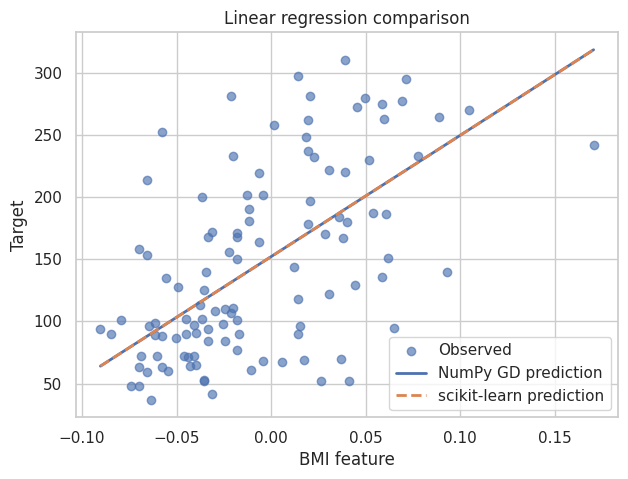

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test_reg[:, 0], y_test_reg, alpha=0.65, label='Observed')

order = np.argsort(X_test_reg[:, 0])
plt.plot(
    X_test_reg[order, 0],
    pred_test_gd[order],
    linewidth=2,
    label='NumPy GD prediction',
)
plt.plot(
    X_test_reg[order, 0],
    pred_test_sk[order],
    linestyle='--',
    linewidth=2,
    label='scikit-learn prediction',
)

plt.xlabel('BMI feature')
plt.ylabel('Target')
plt.title('Linear regression comparison')
plt.legend()
plt.show()

### Activity 3 — What did the comparison verify?

1. Are the two fitted lines similar?
- yes, they are identical: the dashed scikit-learn line lies exactly on top of the NumPy line, rising from about 65 at the lowest BMI to about 320 at the highest

2. Are the errors similar?
- yes, they are the same: MAE 49.81 and RMSE 61.45 for both models

3. What does this support about the NumPy implementation?
- our gradient formulas and update steps are correct: 250 steps of gradient descent on the scaled data reach the same line that scikit-learn computes directly, and converting the predictions back with `y_std` and `y_mean` works as well

4. Why does similarity to scikit-learn not prove that a one-feature linear model is adequate?
- it only shows that our code finds the same best straight line, not that a straight line through BMI alone describes the target well. In the plot the observed points scatter widely around the line: at the same BMI the target can be anywhere from about 50 to about 300, and on average the prediction is off by about 50 (MAE). Both models share this weakness, because they use the same single feature and the same straight line

## 5. From a line to a probability: logistic regression

A linear score can take any value. Binary classification needs a value between 0 and 1.

The sigmoid transformation is

$$
\sigma(z)=\frac{1}{1+e^{-z}}.
$$

Logistic regression models

$$
P(y=1\mid x)=\sigma(w^Tx+b).
$$

The model produces a **probability**. A threshold then turns that probability into a class.

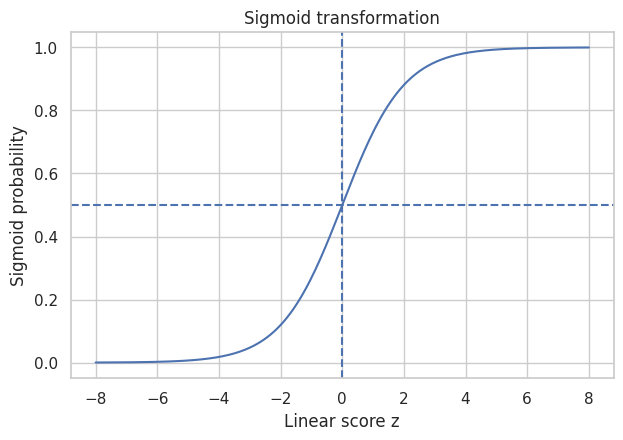

In [11]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


z_values = np.linspace(-8, 8, 300)

plt.figure(figsize=(7, 4.5))
plt.plot(z_values, sigmoid(z_values))
plt.axhline(0.5, linestyle='--')
plt.axvline(0, linestyle='--')
plt.xlabel('Linear score z')
plt.ylabel('Sigmoid probability')
plt.title('Sigmoid transformation')
plt.show()

### Stop and explain

1. What probability corresponds to `z=0`?
- 0.5: the two dashed lines cross on the curve at `z = 0`, and the formula gives the same, because `e^0 = 1` and `1 / (1 + 1) = 0.5`

2. Can a larger positive score reduce the predicted probability?
- no: the curve only rises from left to right. For large scores, from about 6 on, it is almost flat near 1, so a larger score barely changes the probability, but it never makes it smaller

3. Is the threshold `0.5` part of model training or a later decision?
- a later decision: training learns `w` and `b`, which give the probability, and the threshold does not appear in the sigmoid formula at all. It is applied afterwards to turn the probability into a class

## 6. An imbalanced classification problem

We generate a dataset with approximately 90% negatives and 10% positives.

Imagine that the positive class represents a case that requires further examination.

In [12]:
X_cls, y_cls = make_classification(
    n_samples=1600,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    weights=[0.90, 0.10],
    class_sep=1.0,
    flip_y=0.02,
    random_state=RANDOM_STATE,
)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.30,
    stratify=y_cls,
    random_state=RANDOM_STATE,
)

pd.Series(y_train_cls).value_counts(normalize=True).rename('proportion')

,proportion
0,0.890179
1,0.109821


### Baseline prediction

A model that always predicts class `0` has no learning ability.

Before computing, predict:

- its accuracy,
- its recall for the positive class,
- whether it is useful for finding positives.

**Answer:**
- accuracy about 0.89: the model is right for every negative case, and negatives are about 89% of the training set. The split uses `stratify`, so the test set should have about the same share
- recall 0: the model never predicts class `1`, so it finds none of the positive cases
- not useful: the positive cases are exactly the ones that need further examination, and it misses all of them, even though its accuracy looks high

In [13]:
baseline_prediction = np.zeros_like(y_test_cls)

baseline_metrics = {
    'accuracy': accuracy_score(y_test_cls, baseline_prediction),
    'precision': precision_score(y_test_cls, baseline_prediction, zero_division=0),
    'recall': recall_score(y_test_cls, baseline_prediction, zero_division=0),
    'F1': f1_score(y_test_cls, baseline_prediction, zero_division=0),
}

pd.Series(baseline_metrics).round(3)

,0
accuracy,0.892
precision,0.000
recall,0.000
F1,0.000


### Activity 4 — Why accuracy is insufficient

Complete:

> The baseline accuracy is high because about 89% of the test cases are negatives, and a model that always predicts `0` gets every one of them right (accuracy 0.892).
>
> The model is useless for the positive class because it never predicts `1`, so it finds none of the positive cases: recall, precision and F1 are all 0.
>
> Therefore, class distribution must be inspected before judging a model by its accuracy, because here an accuracy of 0.892 can be reached without learning anything.

### Fit logistic regression correctly

The scaler is fitted on training data only. The model is also fitted on training data only.

In [14]:
cls_scaler = StandardScaler()
X_train_cls_scaled = cls_scaler.fit_transform(X_train_cls)
X_test_cls_scaled = cls_scaler.transform(X_test_cls)

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
)
logistic_model.fit(X_train_cls_scaled, y_train_cls)

positive_probability = logistic_model.predict_proba(X_test_cls_scaled)[:, 1]

## 7. The decision threshold changes errors, not probabilities

We compare three thresholds.

Predict before running:

| Threshold | Expected positive predictions | Expected recall | Expected precision |
|---:|---|---|---|
| 0.30 |  |  |  |
| 0.50 |  |  |  |
| 0.70 |  |  |  |

In [ ]:
def metrics_at_threshold(y_true, probability, threshold):
    prediction = (probability >= threshold).astype(int)
    return {
        'threshold': threshold,
        'predicted positives': int(prediction.sum()),
        'accuracy': accuracy_score(y_true, prediction),
        'precision': precision_score(y_true, prediction, zero_division=0),
        'recall': recall_score(y_true, prediction, zero_division=0),
        'F1': f1_score(y_true, prediction, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, probability),
    }


threshold_table = pd.DataFrame([
    metrics_at_threshold(y_test_cls, positive_probability, threshold)
    for threshold in [0.30, 0.50, 0.70]
])

threshold_table.round(3)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for axis, threshold in zip(axes, [0.30, 0.50, 0.70]):
    prediction = (positive_probability >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test_cls,
        prediction,
        ax=axis,
        colorbar=False,
    )
    axis.set_title(f'Threshold = {threshold}')

plt.tight_layout()
plt.show()

### Activity 5 — Choose a threshold for a stated purpose

Suppose missing a positive case is more costly than sending an extra negative case for examination.

1. Which threshold would you initially prefer?
2. Which metric supports your choice?
3. What cost does your choice increase?
4. Why is there no universally optimal threshold without context?

## 8. Guided AI study activity — learning rate and threshold are not the same

Write your own explanation first:

> The learning rate controls __________, while the decision threshold controls __________.

Then use this prompt:

```text
Act as a patient machine-learning tutor.
Do not give me a finished explanation.
Ask me exactly four short questions, one at a time, that help me distinguish:
1. a model parameter,
2. an optimisation setting,
3. a predicted probability,
4. a decision threshold.
After my fourth answer, ask me to give one concrete example.
```

Close the chat and record only:

**One distinction I initially confused:**  

**My corrected explanation:**  

**A concrete example:**

## 9. Assessed task — Evidence-based threshold recommendation (2 points)

Use the same test probabilities and evaluate at least **five thresholds** between `0.10` and `0.90`.

Choose one of these contexts:

- **Screening:** false negatives are much more costly.
- **Limited intervention capacity:** false positives are costly.

Submit:

1. the selected context,
2. a table or plot comparing thresholds,
3. your recommended threshold,
4. the main metric supporting the recommendation,
5. the error type that increases as a trade-off,
6. one limitation of using this synthetic dataset,
7. one sentence explaining why the threshold choice does not retrain the model.

### Marking

| Criterion | Points |
|---|---:|
| Threshold comparison is correct | 0.75 |
| Recommendation matches the stated context | 0.50 |
| Trade-off is explained using errors or metrics | 0.50 |
| Limitation and model/threshold distinction are stated | 0.25 |

In [ ]:
CUSTOM_THRESHOLDS = np.linspace(0.10, 0.90, 9)

custom_threshold_results = pd.DataFrame([
    metrics_at_threshold(
        y_test_cls,
        positive_probability,
        threshold,
    )
    for threshold in CUSTOM_THRESHOLDS
])

custom_threshold_results.round(3)

In [ ]:
plt.figure(figsize=(9, 5))

for metric in ['precision', 'recall', 'F1']:
    plt.plot(
        custom_threshold_results['threshold'],
        custom_threshold_results[metric],
        marker='o',
        label=metric,
    )

plt.xlabel('Decision threshold')
plt.ylabel('Metric value')
plt.title('Threshold trade-offs')
plt.ylim(0, 1.05)
plt.legend()
plt.show()

### Your recommendation

**Context:**  

**Recommended threshold:**  

**Supporting evidence:**  

**Trade-off:**  

**Limitation:**  

**Why this does not retrain the model:**

# End-of-lab self-check

- [ ] I can explain a residual and MSE.
- [ ] I can interpret the sign of a gradient.
- [ ] I can perform one update of `w` and `b`.
- [ ] I can explain why a learning rate may be too small or too large.
- [ ] I can distinguish linear and logistic regression outputs.
- [ ] I can explain why accuracy is misleading under imbalance.
- [ ] I can read a confusion matrix.
- [ ] I can explain the precision–recall trade-off.
- [ ] I can distinguish training from threshold selection.
- [ ] I can identify leakage in preprocessing.

Exercise 6 will replace one linear decision rule with recursive, axis-aligned decisions and ensembles of trees.